# Week 5: Temperature, rPPG + audio, transformer, literature comparison

**Supervisor suggestions this week**
1. Try rPPG + audio, starting with MCD (**done first here**).
2. Try a transformer.
3. Compare with literature.
4. Proceed with another dataset (LVT request pending; see the decision gate).

**Starting point (weeks 2 and 4).** On MCD-rPPG, nothing beats the constant for temperature (test MAE 0.093 °C), not even oracle heart rate. MCD temperatures have std 0.13 °C and no fevers. Temperature can explain at most ~0.8 % of heart-rate variance.

**What this notebook adds**

| Phase | What | Answers |
|---|---|---|
| 0 | Setup, MCD sessions, same patient split as week 4 | constant MAE ≈ 0.0929 |
| 1 | **Audio audit**: do the MCD videos contain a usable audio track? | is rPPG + audio possible on MCD? |
| 2 | Audio features + **audio positive controls** (breathing rate vs `respiratory`, before/after) | does the audio carry physiology? |
| 3 | Tabular fusion: demographics, rPPG, audio, rPPG + audio | does audio add anything? |
| 4 | **Transformer** on rPPG pulse windows (+ demographics / audio token) with positive and negative controls | can a stronger model find what feature models missed? |
| 5 | Literature comparison table | where we stand vs published numbers |
| 6 | Results + decision gate | |

**Protocol, unchanged from week 4:**
- Patient-level split `random_state=43`.
- Every model is compared with the constant (train median) on the same rows.
- Patient-bootstrap 95 % interval on the skill (% MAE reduction).

**Controls (new).**
- A model that "learns nothing" on temperature only proves something if the same pipeline **can** learn a target that has signal. That target is the positive control: heart rate for the transformer, breathing rate for audio.
- Shuffled labels are the negative control: they must give ≈ 0 skill.

## 0. Setup
Paths follow weeks 2–4. Leave `SIGNAL_CACHE` / `FEATURE_TABLES` as they are if your week-3 outputs are in the default place; the loaders print what they find.

In [1]:
import os, re, sys, json, glob, time, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sps, stats
from scipy.io import wavfile
from scipy.fft import dct
from sklearn.model_selection import train_test_split, GroupKFold, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
try:
    display
except NameError:
    display = print

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not os.environ.get("W5_NO_DRIVE"):
    from google.colab import drive
    drive.mount("/content/drive")

MCD_ROOT = os.environ.get("W5_MCD_ROOT", "/content/drive/MyDrive/MCD_rPPG")
MCD_DB   = os.path.join(MCD_ROOT, "db.csv")
OUT_DIR  = os.environ.get("W5_OUT_DIR", os.path.join(MCD_ROOT, "week5_outputs"))
AUDIO_CACHE = os.path.join(OUT_DIR, "audio_wav")          # extracted 16 kHz mono wavs (deletable)

# Week-3 outputs (600 patients, FullHD camera). Loaders try these in order.
SIGNAL_CACHE = os.environ.get("W5_SIGNAL_CACHE",
                              os.path.join(MCD_ROOT, "week3_stress_rppg600/features/signals_30hz.npz"))
FEATURE_TABLES = [p for p in [
    os.environ.get("W5_RPPG_FEATURES", ""),
    os.path.join(MCD_ROOT, "week3_stress_rppg600/features/session_features.csv"),
    os.path.join(MCD_ROOT, "results/week2_baselines/features_rppg.csv"),
] if p]
RPPG_FEATURE_COLS = None     # None = auto (columns starting with 'rppg'); or give an explicit list

SEED = 43
N_BOOT = 2000
FS = 30.0                    # signal cache sampling rate (Hz)
WIN_S, STRIDE_S = 20, 10     # transformer windows
AUDIO_SR = 16000
AUDIT_PER_CAMERA = 40        # sessions probed per camera in the quick audit
POS_FALLBACK_MAX = int(os.environ.get("W5_POS_MAX", "0"))   # >0: compute POS from video if no cache (slow)

os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(AUDIO_CACHE, exist_ok=True)
RESULTS = []
print("db:", MCD_DB, os.path.exists(MCD_DB))
print("signal cache:", SIGNAL_CACHE, os.path.exists(SIGNAL_CACHE))
print("feature tables:", [(p, os.path.exists(p)) for p in FEATURE_TABLES])

Mounted at /content/drive
db: /content/drive/MyDrive/MCD_rPPG/db.csv True
signal cache: /content/drive/MyDrive/MCD_rPPG/week3_stress_rppg600/features/signals_30hz.npz True
feature tables: [('/content/drive/MyDrive/MCD_rPPG/week3_stress_rppg600/features/session_features.csv', True), ('/content/drive/MyDrive/MCD_rPPG/results/week2_baselines/features_rppg.csv', True)]


In [2]:
# ---- Shared helpers (same as week 4) ----
def make_models():
    return {
        "Ridge": Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                           ("m", RidgeCV(alphas=np.logspace(-3, 3, 13)))]),
        "HGB": HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, learning_rate=0.05,
                                             min_samples_leaf=20, random_state=SEED),
    }

def group_boot_skill(abs_model, abs_ref, groups, n=N_BOOT, seed=SEED):
    abs_model, abs_ref = np.asarray(abs_model, float), np.asarray(abs_ref, float)
    _, inv = np.unique(np.asarray(groups), return_inverse=True)
    sa, sb, cnt = np.bincount(inv, abs_model), np.bincount(inv, abs_ref), np.bincount(inv).astype(float)
    idx = np.random.default_rng(seed).integers(0, len(cnt), size=(n, len(cnt)))
    with np.errstate(divide="ignore", invalid="ignore"):
        sk = 100 * (1 - (sa[idx].sum(1) / cnt[idx].sum(1)) / (sb[idx].sum(1) / cnt[idx].sum(1)))
    sk = sk[np.isfinite(sk)]
    return tuple(np.percentile(sk, [2.5, 97.5])) if len(sk) else (np.nan, np.nan)

def evaluate(phase, target, model, features, y_true, y_pred, y_ref, groups, ref_name="constant", show=True):
    y_true, y_pred, y_ref = (np.asarray(a, float) for a in (y_true, y_pred, y_ref))
    am, ar = np.abs(y_true - y_pred), np.abs(y_true - y_ref)
    mae, mae_ref = am.mean(), ar.mean()
    skill = 100 * (1 - mae / mae_ref) if mae_ref > 0 else np.nan
    lo, hi = group_boot_skill(am, ar, groups)
    rho = stats.spearmanr(y_true, y_pred)[0] if np.std(y_pred) > 0 else np.nan
    row = dict(phase=phase, target=target, model=model, features=features, n=len(y_true),
               MAE=round(mae, 4), ref=ref_name, ref_MAE=round(mae_ref, 4), skill_pct=round(skill, 2),
               skill_lo=round(lo, 2), skill_hi=round(hi, 2), spearman=round(rho, 3) if np.isfinite(rho) else np.nan,
               pred_sd=round(float(np.std(y_pred)), 4), label_sd=round(float(np.std(y_true)), 4))
    RESULTS.append(row)
    if show:
        print(f"[{phase}] {target:<12} {model:<12} {features:<28} MAE {mae:.4f} vs {ref_name} {mae_ref:.4f} "
              f"-> skill {skill:+6.2f}% [{lo:+.2f}, {hi:+.2f}] | rho {row['spearman']} | pred sd {row['pred_sd']}")
    return row

In [3]:
# ---- MCD sessions and the week-4 patient split ----
db = pd.read_csv(MCD_DB)
LABEL_COLS = ["weight", "height", "bmi", "age", "upper_ap", "lower_ap", "saturation", "temperature", "hemoglobin",
              "glycated_hemoglobin", "cholesterol", "respiratory", "rigidity", "pulse", "stress"]
sess = (db.drop_duplicates(["patient_id", "step"])
          [["patient_id", "step", "age", "sex", "bmi", "temperature", "pulse", "respiratory", "stress"]]
          .reset_index(drop=True))
sess["sex_male"] = sess["sex"].astype(str).str.upper().str[0].map({"M": 1.0, "F": 0.0})
sess["post_exercise"] = (sess["step"] == "after").astype(float)
sess["sid"] = sess["patient_id"].astype(str) + "_" + sess["step"]
patients = pd.unique(db["patient_id"])
tr_p, te_p = train_test_split(patients, test_size=0.2, random_state=SEED)
sess["split"] = np.where(sess["patient_id"].isin(te_p), "test", "train")
TR, TE = sess["split"].eq("train"), sess["split"].eq("test")
const_t = sess.loc[TR, "temperature"].median()
print(f"{len(sess)} sessions | train {TR.sum()} / test {TE.sum()}")
print(f"Temperature: std {sess.temperature.std():.3f} °C, max {sess.temperature.max():.1f} | "
      f"constant test MAE {np.abs(sess.loc[TE,'temperature']-const_t).mean():.4f} (week 4: 0.0929)")
DEMO = ["age", "sex_male", "bmi", "post_exercise"]

1200 sessions | train 960 / test 240
Temperature: std 0.133 °C, max 37.5 | constant test MAE 0.0929 (week 4: 0.0929)


## Phase 1: Audio audit
The MCD paper describes subjects sitting **motionless and silent** for 3 minutes, and the dataset card lists only video and text, so the videos may have no audio track at all. Before building anything, check:
1. **Quick probe:** `ffprobe` on `AUDIT_PER_CAMERA` sessions per camera.
2. **Full probe** of the camera(s) that have audio.
3. **Loudness check:** decode a few tracks and measure the level, so a track of digital silence is not mistaken for usable audio.

`AUDIO_USABLE` gates Phases 2–3 and the audio variant of the transformer.

In [4]:
def ffprobe_audio(path):
    """Return dict with audio-stream info for one file (has_audio False if none / unreadable)."""
    out = dict(exists=os.path.exists(path), has_audio=False, codec=None, sr=np.nan, channels=np.nan, dur=np.nan)
    if not out["exists"]:
        return out
    try:
        r = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "a", "-show_entries",
                            "stream=codec_name,sample_rate,channels,duration", "-of", "json", path],
                           capture_output=True, text=True, timeout=60)
        st = json.loads(r.stdout or "{}").get("streams", [])
    except Exception as e:
        out["error"] = str(e); return out
    if st:
        s = st[0]
        out.update(has_audio=True, codec=s.get("codec_name"), sr=float(s.get("sample_rate", "nan")),
                   channels=float(s.get("channels", "nan")), dur=float(s.get("duration", "nan") or "nan"))
    return out

assert subprocess.run(["which", "ffprobe"], capture_output=True).returncode == 0, \
    "ffprobe not found: run !apt-get -qq install ffmpeg"

rng = np.random.default_rng(SEED)
quick = []
for cam, g in db.groupby("camera"):
    pick = g.sample(min(AUDIT_PER_CAMERA, len(g)), random_state=SEED)
    for _, r in pick.iterrows():
        quick.append({"camera": cam, "video": r["video"], **ffprobe_audio(os.path.join(MCD_ROOT, r["video"]))})
quick = pd.DataFrame(quick)
print("Quick audit (per camera):")
display(quick.groupby("camera").agg(probed=("exists", "size"), found=("exists", "sum"),
                                    with_audio=("has_audio", "sum"), codec=("codec", "first"),
                                    sr=("sr", "median"), dur_s=("dur", "median")))

Quick audit (per camera):


,probed,found,with_audio,codec,sr,dur_s
camera,,,,,,
FullHDwebcam,40,0,0,None,NaN,NaN
IriunWebcam,40,0,0,None,NaN,NaN
USBVideo,40,0,0,None,NaN,NaN


In [6]:
def decode_wav(video_rel, sr=AUDIO_SR):
    """Extract mono `sr` Hz wav to the cache (once) and return the float32 signal, or None."""
    src = os.path.join(MCD_ROOT, video_rel)
    dst = os.path.join(AUDIO_CACHE, os.path.basename(video_rel).rsplit(".", 1)[0] + ".wav")
    if not os.path.exists(dst):
        r = subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", src, "-vn", "-ac", "1", "-ar", str(sr),
                            "-f", "wav", dst], capture_output=True, text=True, timeout=600)
        if r.returncode != 0 or not os.path.exists(dst):
            return None
    _, x = wavfile.read(dst)
    if np.issubdtype(x.dtype, np.integer):
        x = x.astype(np.float32) / float(np.iinfo(x.dtype).max)
    return x.astype(np.float32).ravel()

def dbfs(x):
    return 20 * np.log10(np.sqrt(np.mean(np.square(x))) + 1e-12)

if quick["exists"].sum() == 0:
    raise FileNotFoundError(f"None of the probed videos exist under {MCD_ROOT}; check MCD_ROOT / the video folder "
                            "before concluding anything about audio.")
audio_cams = quick[quick["exists"]].groupby("camera")["has_audio"].mean()
audio_cams = audio_cams[audio_cams > 0.5].index.tolist()
print("Cameras with audio in the quick probe:", audio_cams or "NONE")

AUDIO_USABLE, AUDIO_CAMERA, audit_full = False, None, None
if audio_cams:
    # prefer the front camera if it has audio
    AUDIO_CAMERA = "FullHDwebcam" if "FullHDwebcam" in audio_cams else audio_cams[0]
    g = db[db["camera"] == AUDIO_CAMERA]
    audit_full = pd.DataFrame([{"patient_id": r.patient_id, "step": r.step, "video": r.video,
                                **ffprobe_audio(os.path.join(MCD_ROOT, r.video))} for r in g.itertuples()])
    cov = audit_full["has_audio"].mean()
    levels = []
    for v in audit_full[audit_full.has_audio].sample(min(8, audit_full.has_audio.sum()), random_state=SEED)["video"]:
        x = decode_wav(v)
        if x is not None and len(x):
            levels.append(dbfs(x))
    med_level = np.median(levels) if levels else -np.inf
    print(f"{AUDIO_CAMERA}: audio in {cov*100:.1f}% of {len(audit_full)} sessions; "
          f"median level of {len(levels)} decoded tracks = {med_level:.1f} dBFS")
    AUDIO_USABLE = cov >= 0.8 and med_level > -70
    if not AUDIO_USABLE:
        print("Audio present but too sparse or silent to use.")
print("\nAUDIO_USABLE =", AUDIO_USABLE)
if not AUDIO_USABLE:
    print("=> rPPG + audio is NOT possible on MCD. Phases 2-3 audio parts and the audio transformer are skipped.\n"
          "   Report this as a dataset limitation; audio needs a dataset recorded with a microphone.")

FileNotFoundError: None of the probed videos exist under /content/drive/MyDrive/MCD_rPPG; check MCD_ROOT / the video folder before concluding anything about audio.

## Phase 2: Audio features and audio positive controls
Runs only if `AUDIO_USABLE`. Subjects are silent, so the plausible physiological content is **breathing sound**, plus room noise. Features (numpy/scipy only, no extra packages):
- Level: RMS mean/std (dBFS), noise floor (10th percentile frame level), and the fraction of frames more than 10 dB above the floor (activity).
- Spectrum: centroid, bandwidth, roll-off, zero-crossing rate, 13 MFCC means and standard deviations.
- **Breathing:** envelope of the 100–1000 Hz band, its dominant frequency in 0.1–0.7 Hz (breaths/min) and that peak's prominence.

**Positive controls.** Breathing rate vs the `respiratory` label (Spearman), and before/after exercise classification (AUC). If audio cannot see breathing or exercise, it cannot be expected to see a 0.1 °C temperature difference.

In [7]:
def mel_filterbank(sr, n_fft, n_mels=26, fmin=50, fmax=None):
    fmax = fmax or sr / 2
    hz2mel = lambda f: 2595 * np.log10(1 + f / 700); mel2hz = lambda m: 700 * (10 ** (m / 2595) - 1)
    pts = mel2hz(np.linspace(hz2mel(fmin), hz2mel(fmax), n_mels + 2))
    bins = np.floor((n_fft + 1) * pts / sr).astype(int)
    fb = np.zeros((n_mels, n_fft // 2 + 1))
    for i in range(1, n_mels + 1):
        l, c, r = bins[i - 1], bins[i], bins[i + 1]
        if c > l: fb[i - 1, l:c] = (np.arange(l, c) - l) / (c - l)
        if r > c: fb[i - 1, c:r] = (r - np.arange(c, r)) / (r - c)
    return fb

_FB = mel_filterbank(AUDIO_SR, 512)

def audio_features(x, sr=AUDIO_SR):
    x = x - np.mean(x)
    if len(x) < sr * 5:
        return None
    hop, n_fft = 160, 512                                          # 10 ms hop
    f, t, Z = sps.stft(x, fs=sr, nperseg=n_fft, noverlap=n_fft - hop, boundary=None)
    P = np.abs(Z) ** 2 + 1e-12                                     # freq x frames
    frame_db = 10 * np.log10(P.sum(0) / n_fft + 1e-12)
    floor = np.percentile(frame_db, 10)
    psum = P.sum(0)
    centroid = (f[:, None] * P).sum(0) / psum
    bandwidth = np.sqrt(((f[:, None] - centroid) ** 2 * P).sum(0) / psum)
    cum = np.cumsum(P, 0) / psum
    rolloff = f[np.argmax(cum >= 0.85, axis=0)]
    zcr = np.mean(np.abs(np.diff(np.sign(x))) > 0)
    mfcc = dct(np.log(_FB @ P + 1e-10), type=2, axis=0, norm="ortho")[:13]
    feats = {"aud_rms_db_mean": frame_db.mean(), "aud_rms_db_std": frame_db.std(), "aud_floor_db": floor,
             "aud_activity": np.mean(frame_db > floor + 10), "aud_centroid": centroid.mean(),
             "aud_bandwidth": bandwidth.mean(), "aud_rolloff": rolloff.mean(), "aud_zcr": zcr}
    for i in range(13):
        feats[f"aud_mfcc{i}_mean"], feats[f"aud_mfcc{i}_std"] = mfcc[i].mean(), mfcc[i].std()
    # breathing: 100-1000 Hz band energy envelope at 100 Hz, dominant 0.1-0.7 Hz component
    band = (f >= 100) & (f <= 1000)
    env = np.log(P[band].sum(0) + 1e-12)                           # 100 Hz frame rate
    env = sps.detrend(env)
    fe, pe = sps.welch(env, fs=sr / hop, nperseg=min(len(env), int(60 * sr / hop)))
    br = (fe >= 0.1) & (fe <= 0.7)
    if br.sum() >= 3:
        k = np.argmax(pe[br])
        feats["aud_breath_rate_bpm"] = fe[br][k] * 60
        feats["aud_breath_prom"] = pe[br][k] / (np.median(pe[br]) + 1e-12)
    else:
        feats["aud_breath_rate_bpm"], feats["aud_breath_prom"] = np.nan, np.nan
    return feats

AUD_COLS = []
if AUDIO_USABLE:
    feat_csv = os.path.join(OUT_DIR, f"audio_features_{AUDIO_CAMERA}.csv")
    if os.path.exists(feat_csv):
        afeat = pd.read_csv(feat_csv)
    else:
        rows, t0 = [], time.time()
        todo = audit_full[audit_full.has_audio]
        for i, r in enumerate(todo.itertuples()):
            x = decode_wav(r.video)
            fts = audio_features(x) if x is not None else None
            if fts:
                rows.append({"patient_id": r.patient_id, "step": r.step, **fts})
            if (i + 1) % 100 == 0:
                print(f"  {i+1}/{len(todo)} files, {time.time()-t0:.0f}s")
        afeat = pd.DataFrame(rows); afeat.to_csv(feat_csv, index=False)
    AUD_COLS = [c for c in afeat.columns if c.startswith("aud_")]
    sess = sess.drop(columns=[c for c in sess.columns if c.startswith("aud_")]).merge(
        afeat, on=["patient_id", "step"], how="left")
    TR, TE = sess["split"].eq("train"), sess["split"].eq("test")
    print(f"Audio features: {len(AUD_COLS)} columns, coverage {sess[AUD_COLS[0]].notna().mean()*100:.1f}% of sessions")

NameError: name 'AUDIO_USABLE' is not defined

In [8]:
if AUDIO_USABLE:
    # Positive control 1: audio breathing rate vs respiratory label
    ok = sess[["aud_breath_rate_bpm", "respiratory"]].dropna()
    r1, p1 = stats.spearmanr(ok["aud_breath_rate_bpm"], ok["respiratory"])
    print(f"Breathing rate (audio) vs respiratory label: Spearman {r1:+.3f} (p={p1:.3g}, n={len(ok)})")
    # Positive control 2: before vs after exercise from audio (grouped CV on all patients)
    X, y, gr = sess[AUD_COLS], sess["post_exercise"].astype(int), sess["patient_id"]
    oof = np.zeros(len(sess))
    for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X, y, gr):
        clf = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                        ("m", LogisticRegression(max_iter=2000, C=0.3))]).fit(X.iloc[a], y.iloc[a])
        oof[b] = clf.predict_proba(X.iloc[b])[:, 1]
    auc_ex = roc_auc_score(y, oof)
    print(f"Before/after exercise from audio: grouped-CV AUC {auc_ex:.3f}")
    # Direct look at temperature
    rho_t = {c: stats.spearmanr(sess[c], sess["temperature"], nan_policy="omit")[0] for c in AUD_COLS}
    top = pd.Series(rho_t).abs().sort_values(ascending=False).head(5)
    print("Largest |Spearman| of audio features with temperature:", top.round(3).to_dict())
    AUDIO_CONTROL = dict(breath_rho=r1, breath_p=p1, exercise_auc=auc_ex)
else:
    AUDIO_CONTROL = {}
    print("Skipped (no usable audio).")

NameError: name 'AUDIO_USABLE' is not defined

## Phase 3: Tabular fusion (demographics, rPPG, audio, rPPG + audio)
rPPG features come from the week-3 600-patient session table (or week 2 if that is all that exists). Columns starting with `rppg` are used by default. Any label column and any contact-PPG column is removed, so nothing leaks. The same Ridge/HGB models and evaluation are used as in week 4; skill is reported vs the constant and vs demographics.

In [9]:
def load_feature_table(paths):
    for p in paths:
        if os.path.exists(p):
            t = pd.read_csv(p)
            if "step" not in t.columns:
                for c in t.columns:
                    if t[c].astype(str).isin(["before", "after"]).mean() > 0.9:
                        t = t.rename(columns={c: "step"}); break
            if "patient_id" not in t.columns or "step" not in t.columns:
                print("skip (no patient_id/step):", p); continue
            if "camera" in t.columns:
                t = t[t["camera"].astype(str).str.contains("FullHD", case=False)]
            return p, t.drop_duplicates(["patient_id", "step"])
    return None, None

ft_path, ftab = load_feature_table(FEATURE_TABLES)
RPPG_COLS = []
if ftab is not None:
    num = [c for c in ftab.select_dtypes("number").columns if c != "patient_id"]
    banned = set(LABEL_COLS) | {"y", "target", "label", "post_exercise", "sex_male"}
    num = [c for c in num if c not in banned and not re.search(r"(^|_)(c?ppg|contact|ecg)(_|$)", c, re.I)]
    if RPPG_FEATURE_COLS:
        RPPG_COLS = [c for c in RPPG_FEATURE_COLS if c in ftab.columns]
    else:
        RPPG_COLS = [c for c in num if c.lower().startswith("rppg")] or num
    sess = sess.drop(columns=[c for c in RPPG_COLS if c in sess.columns]).merge(
        ftab[["patient_id", "step"] + RPPG_COLS], on=["patient_id", "step"], how="left")
    TR, TE = sess["split"].eq("train"), sess["split"].eq("test")
    print(f"rPPG features from {ft_path}: {len(RPPG_COLS)} columns, "
          f"coverage {sess[RPPG_COLS].notna().any(axis=1).mean()*100:.1f}% of sessions")
    print("  ", RPPG_COLS[:15], "..." if len(RPPG_COLS) > 15 else "")
else:
    print("No rPPG feature table found; tabular rPPG rows are skipped (the transformer still runs on signals).")

rPPG features from /content/drive/MyDrive/MCD_rPPG/week3_stress_rppg600/features/session_features.csv: 32 columns, coverage 99.9% of sessions
   ['rppg_face_missing_frac', 'rppg_dup_frac', 'rppg_used_ts', 'rppg_fps_measured', 'rppg_duration_s', 'rppg_snr_face', 'rppg_skin_r', 'rppg_skin_g', 'rppg_skin_lum', 'rppg_snr_forehead', 'rppg_snr_left_cheek', 'rppg_snr_right_cheek', 'rppg_hr', 'rppg_snr', 'rppg_hr_win_sd'] ...


In [10]:
def run_tabular(name, cols, target="temperature", phase="P3"):
    if not cols:
        return
    y_tr, y_te = sess.loc[TR, target], sess.loc[TE, target]
    ref = np.full(TE.sum(), y_tr.median())
    for mn, m in make_models().items():
        m.fit(sess.loc[TR, cols], y_tr)
        evaluate(phase, target, mn, name, y_te, m.predict(sess.loc[TE, cols]), ref, sess.loc[TE, "patient_id"])

SETS = {"demographics": DEMO}
if RPPG_COLS: SETS["rPPG"] = RPPG_COLS; SETS["demo + rPPG"] = DEMO + RPPG_COLS
if AUD_COLS:  SETS["audio"] = AUD_COLS; SETS["demo + audio"] = DEMO + AUD_COLS
if RPPG_COLS and AUD_COLS:
    SETS["rPPG + audio"] = RPPG_COLS + AUD_COLS; SETS["demo + rPPG + audio"] = DEMO + RPPG_COLS + AUD_COLS
for name, cols in SETS.items():
    run_tabular(name, cols)

# Does audio ADD to rPPG? Same model with vs without the audio block (reference = without audio).
if RPPG_COLS and AUD_COLS:
    for mn in make_models():
        base = make_models()[mn].fit(sess.loc[TR, DEMO + RPPG_COLS], sess.loc[TR, "temperature"])
        full = make_models()[mn].fit(sess.loc[TR, DEMO + RPPG_COLS + AUD_COLS], sess.loc[TR, "temperature"])
        evaluate("P3", "temperature", mn, "audio added to demo+rPPG", sess.loc[TE, "temperature"],
                 full.predict(sess.loc[TE, DEMO + RPPG_COLS + AUD_COLS]),
                 base.predict(sess.loc[TE, DEMO + RPPG_COLS]), sess.loc[TE, "patient_id"], ref_name="no audio")

[P3] temperature  Ridge        demographics                 MAE 0.1048 vs constant 0.0929 -> skill -12.82% [-22.65, -5.36] | rho 0.089 | pred sd 0.005
[P3] temperature  HGB          demographics                 MAE 0.1000 vs constant 0.0929 -> skill  -7.62% [-18.46, +0.87] | rho 0.094 | pred sd 0.0457
[P3] temperature  Ridge        rPPG                         MAE 0.1103 vs constant 0.0929 -> skill -18.71% [-37.11, -7.05] | rho -0.011 | pred sd 0.0579
[P3] temperature  HGB          rPPG                         MAE 0.1070 vs constant 0.0929 -> skill -15.12% [-26.88, -6.19] | rho 0.006 | pred sd 0.035
[P3] temperature  Ridge        demo + rPPG                  MAE 0.1104 vs constant 0.0929 -> skill -18.79% [-37.44, -7.05] | rho 0.007 | pred sd 0.0599
[P3] temperature  HGB          demo + rPPG                  MAE 0.1027 vs constant 0.0929 -> skill -10.58% [-22.77, -1.26] | rho 0.12 | pred sd 0.038


## Phase 4: Transformer on rPPG pulse windows
**Input:** the 30 Hz rPPG signal cached in week 3 (600 patients × 2 sessions), cut into 20 s windows (10 s stride) and z-scored per window. A session's prediction is the mean over its windows.

**Model.** A small time-series transformer:
- 1 s patches (30 samples) → 20 tokens, linear patch embedding, d = 64.
- 3 pre-norm encoder layers, 4 heads, CLS token and learned positions.
- Optional **auxiliary token** (demographics; plus audio PCA components when audio is usable). This is the rPPG + audio fusion.
- L1 loss on a standardised target; AdamW; early stopping on 10 % of training patients; 3 seeds averaged.

**Runs** (all on the same split as above):

| Run | Target | Input | Purpose |
|---|---|---|---|
| T0 | heart rate | rPPG | **positive control**: must clearly beat the constant |
| T1 | temperature | rPPG | main test |
| T2 | temperature | rPPG + demographics token | |
| T3 | temperature | rPPG + demographics + audio token | rPPG + audio fusion (only if audio usable) |
| T4 | temperature | contact PPG (if cached) | ceiling for a perfect rPPG |
| T5 | shuffled temperature | rPPG | **negative control**: must give ≈ 0 |

Use a GPU runtime (Runtime → Change runtime type → T4). On CPU it still runs, but more slowly.

In [11]:
SESSION_RE = re.compile(r"(\d+)\D+?(before|after)", re.I)

def _sid_from(x):
    m = SESSION_RE.search(str(x))
    return f"{int(m.group(1))}_{m.group(2).lower()}" if m else None

def _kind(name):
    n = name.lower()
    if "rppg" in n or "pos" in n: return "rppg"
    if re.search(r"(^|[^r])ppg|contact|cppg", n): return "ppg"
    return None

def load_signal_cache(path):
    """Return ({sid: rppg}, {sid: contact_ppg}). Handles per-session keys or id-array + stacked/object arrays."""
    z = np.load(path, allow_pickle=True)
    keys = list(z.keys())
    print(f"cache keys ({len(keys)}):", keys[:12], "..." if len(keys) > 12 else "")
    out = {"rppg": {}, "ppg": {}}
    per = [k for k in keys if SESSION_RE.search(k)]
    if len(per) >= 10:                                   # layout A: one key per session (and signal type)
        for k in per:
            kind = _kind(k.replace(SESSION_RE.search(k).group(0), "")) or "rppg"
            out[kind][_sid_from(k)] = np.asarray(z[k], float).ravel()
        return out["rppg"], out["ppg"]
    # layout B: ids + arrays
    n_by_key = {k: (len(z[k]) if z[k].ndim else 0) for k in keys}
    ids = None
    if "patient_id" in keys and "step" in keys:
        ids = [f"{int(p)}_{str(s).lower()}" for p, s in zip(z["patient_id"], z["step"])]
    else:
        for k in keys:
            if z[k].ndim == 1 and z[k].dtype.kind in "USO" and len(z[k]) and _sid_from(z[k][0]):
                ids = [_sid_from(v) for v in z[k]]; break
    if ids is None:
        raise ValueError("Could not find session ids in the cache. Keys: " + str(keys))
    for k in keys:
        kind = _kind(k)
        if kind and n_by_key[k] == len(ids):
            for sid, s in zip(ids, z[k]):
                if sid and s is not None:
                    out[kind][sid] = np.asarray(s, float).ravel()
    if not out["rppg"]:
        raise ValueError("No rPPG array recognised in the cache. Keys: " + str(keys))
    return out["rppg"], out["ppg"]

# ---- optional fallback: POS from the FullHD video (slow; only if no cache) ----
def pos_from_video(path, fs_out=FS, max_s=200):
    import cv2
    cap = cv2.VideoCapture(path); fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    det = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
    rgb, box, i = [], None, 0
    while i < int(max_s * fps):
        ok, fr = cap.read()
        if not ok: break
        if i % int(fps) == 0 or box is None:
            g = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)
            f = det.detectMultiScale(g, 1.1, 5, minSize=(60, 60))
            if len(f): box = max(f, key=lambda b: b[2] * b[3])
            elif box is None:
                h, w = g.shape; box = (w // 4, h // 4, w // 2, h // 2)
        x, y, w, h = box
        roi = fr[y + h // 5: y + 4 * h // 5, x + w // 5: x + 4 * w // 5]
        rgb.append(roi.reshape(-1, 3).mean(0)[::-1]); i += 1
    cap.release()
    C = np.asarray(rgb, float)
    if len(C) < fps * 10: return None
    L = int(1.6 * fps); H = np.zeros(len(C))
    for t in range(len(C) - L):
        Cn = C[t:t + L] / (C[t:t + L].mean(0) + 1e-9)
        S = Cn @ np.array([[0, 1, -1], [-2, 1, 1]]).T
        h_ = S[:, 0] + (S[:, 0].std() / (S[:, 1].std() + 1e-9)) * S[:, 1]
        H[t:t + L] += h_ - h_.mean()
    b, a = sps.butter(3, [0.7 / (fps / 2), 3.0 / (fps / 2)], "band")
    H = sps.filtfilt(b, a, H)
    tt = np.arange(len(H)) / fps
    return np.interp(np.arange(0, tt[-1], 1 / fs_out), tt, H)

if os.path.exists(SIGNAL_CACHE):
    RPPG_SIG, PPG_SIG = load_signal_cache(SIGNAL_CACHE)
elif POS_FALLBACK_MAX > 0:
    print("No cache: computing POS from FullHD videos (slow)...")
    RPPG_SIG, PPG_SIG = {}, {}
    g = db[db["camera"] == "FullHDwebcam"].head(POS_FALLBACK_MAX)
    for r in g.itertuples():
        s = pos_from_video(os.path.join(MCD_ROOT, r.video))
        if s is not None: RPPG_SIG[f"{r.patient_id}_{r.step}"] = s
else:
    raise FileNotFoundError("Set SIGNAL_CACHE to the week-3 signals_30hz.npz, or set W5_POS_MAX>0 for the POS fallback.")

print(f"rPPG signals: {len(RPPG_SIG)} sessions | contact PPG: {len(PPG_SIG)} sessions")
lens = np.array([len(v) for v in RPPG_SIG.values()]) / FS
print(f"rPPG length: median {np.median(lens):.0f}s (min {lens.min():.0f}s)")

cache keys (2398): ['rppg_1020_after', 'ppg_1020_after', 'rppg_1020_before', 'ppg_1020_before', 'rppg_1024_after', 'ppg_1024_after', 'rppg_1024_before', 'ppg_1024_before', 'rppg_1035_after', 'ppg_1035_after', 'rppg_1035_before', 'ppg_1035_before'] ...
rPPG signals: 1199 sessions | contact PPG: 1199 sessions
rPPG length: median 180s (min 30s)


In [12]:
def welch_hr(s, fs=FS):
    s = np.asarray(s, float); s = s[np.isfinite(s)]
    if len(s) < fs * 10: return np.nan
    f, p = sps.welch(sps.detrend(s), fs=fs, nperseg=int(min(len(s), fs * 20)))
    m = (f >= 0.7) & (f <= 3.0)
    return f[m][np.argmax(p[m])] * 60

# positive-control target: HR from contact PPG when cached (cleanest), else the spot pulse reading
if len(PPG_SIG) > 0.5 * len(sess):
    sess["hr_target"] = sess["sid"].map(lambda k: welch_hr(PPG_SIG[k]) if k in PPG_SIG else np.nan)
    HR_TARGET_NAME = "HR (contact PPG)"
else:
    sess["hr_target"] = sess["pulse"]; HR_TARGET_NAME = "HR (spot pulse)"
TR, TE = sess["split"].eq("train"), sess["split"].eq("test")
print("Positive-control target:", HR_TARGET_NAME, "| sd", round(sess["hr_target"].std(), 2), "BPM")

def make_windows(sig_dict, sids, win=int(WIN_S * FS), stride=int(STRIDE_S * FS)):
    X, owner = [], []
    for k in sids:
        s = sig_dict.get(k)
        if s is None: continue
        s = np.nan_to_num(np.asarray(s, np.float32))
        for st in range(0, len(s) - win + 1, stride):
            w = s[st:st + win]; sd = w.std()
            if sd > 1e-8:
                X.append((w - w.mean()) / sd); owner.append(k)
    return np.asarray(X, np.float32).reshape(-1, win), np.asarray(owner)

def aux_matrix(cols, n_pca=None):
    """Standardised (train stats) auxiliary features per session; optional PCA on a block."""
    if not cols: return None
    A = sess[cols].astype(float)
    imp = SimpleImputer(strategy="median").fit(A[TR]); sc = StandardScaler().fit(imp.transform(A[TR]))
    M = sc.transform(imp.transform(A))
    if n_pca and M.shape[1] > n_pca:
        M = PCA(n_pca, random_state=SEED).fit(M[TR.to_numpy()]).transform(M)
        M = M / (M[TR.to_numpy()].std(0) + 1e-9)
    return pd.DataFrame(M, index=sess["sid"]).astype(np.float32)

Positive-control target: HR (contact PPG) | sd 13.25 BPM


In [13]:
import torch, torch.nn as nn
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE)

class PulseTransformer(nn.Module):
    def __init__(self, win=int(WIN_S * FS), patch=30, d=64, depth=3, heads=4, n_aux=0, drop=0.1):
        super().__init__()
        assert win % patch == 0
        self.patch, n_tok = patch, win // patch
        self.embed = nn.Linear(patch, d)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.aux = nn.Sequential(nn.Linear(n_aux, d), nn.GELU(), nn.Linear(d, d)) if n_aux else None
        self.pos = nn.Parameter(torch.randn(1, n_tok + 1 + (1 if n_aux else 0), d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, drop, batch_first=True, norm_first=True,
                                           activation="gelu")
        self.enc = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm, self.head = nn.LayerNorm(d), nn.Linear(d, 1)

    def forward(self, x, aux=None):
        B = x.shape[0]
        toks = [self.cls.expand(B, -1, -1)]
        if self.aux is not None:
            toks.append(self.aux(aux).unsqueeze(1))
        toks.append(self.embed(x.view(B, -1, self.patch)))
        h = torch.cat(toks, 1)
        h = self.enc(h + self.pos[:, :h.shape[1]])
        return self.head(self.norm(h[:, 0])).squeeze(-1)

def train_transformer(sig_dict, target, aux_df=None, seed=0, epochs=40, patience=8, bs=256, lr=3e-4,
                      shuffle_labels=False):
    torch.manual_seed(seed); np.random.seed(seed)
    y_all = sess.set_index("sid")[target].astype(float)
    if shuffle_labels:                               # permute labels across TRAIN patients (patient level)
        tr_ids = sess.loc[TR, "patient_id"].unique()
        perm = dict(zip(tr_ids, np.random.default_rng(seed).permutation(tr_ids)))
        lab = sess.set_index(["patient_id", "step"])[target]
        y_all = y_all.copy()
        for r in sess[TR].itertuples():
            y_all[r.sid] = lab.get((perm[r.patient_id], r.step), np.nan)
    tr_s = sess.loc[TR, "patient_id"].unique()
    va_p = np.random.default_rng(seed).choice(tr_s, size=max(1, len(tr_s) // 10), replace=False)
    part = {"fit": sess[TR & ~sess.patient_id.isin(va_p)], "val": sess[TR & sess.patient_id.isin(va_p)],
            "test": sess[TE]}
    data = {}
    for k, d in part.items():
        d = d[d["sid"].map(y_all).notna()]
        X, own = make_windows(sig_dict, d["sid"])
        A = aux_df.loc[own].to_numpy() if aux_df is not None else None
        data[k] = (X, own, A)
    y_fit = y_all.loc[data["fit"][1]].to_numpy(np.float32)
    mu, sd = float(np.median(y_fit)), float(np.std(y_fit) or 1.0)
    model = PulseTransformer(n_aux=0 if aux_df is None else aux_df.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    T = lambda a: torch.from_numpy(np.ascontiguousarray(a)).to(DEVICE)

    def predict(split):
        X, own, A = data[split]
        model.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(X), 1024):
                out.append(model(T(X[i:i+1024]), T(A[i:i+1024]) if A is not None else None).cpu().numpy())
        p = np.concatenate(out).astype(float) * sd + mu if out else np.array([])
        return pd.Series(p).groupby(own).mean()       # session-level mean over windows

    X, own, A = data["fit"]; yz = ((y_fit - mu) / sd).astype(np.float32)
    best, best_state, bad = np.inf, None, 0
    for ep in range(epochs):
        model.train()
        idx = np.random.permutation(len(X))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]
            loss = nn.functional.l1_loss(model(T(X[b]), T(A[b]) if A is not None else None), T(yz[b]))
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        pv = predict("val"); v = np.abs(pv.to_numpy() - y_all.loc[pv.index].to_numpy()).mean()
        if v < best - 1e-6:
            best, bad = v, 0
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    if best_state is not None:
        model.load_state_dict(best_state)
    return predict("test"), ep + 1

def run_transformer(tag, sig_dict, target, aux_df=None, seeds=(0, 1, 2), shuffle_labels=False, **kw):
    preds, eps = [], []
    t0 = time.time()
    for s in seeds:
        p, e = train_transformer(sig_dict, target, aux_df, seed=s, shuffle_labels=shuffle_labels, **kw)
        preds.append(p); eps.append(e)
    p = pd.concat(preds, axis=1).mean(1)
    te = sess[TE].set_index("sid").loc[p.index]
    y_ref = np.full(len(te), sess.loc[TR, target].median())
    evaluate("P4", ("shuffled " if shuffle_labels else "") + target, "Transformer", tag,
             te[target], p.to_numpy(), y_ref, te["patient_id"])
    print(f"    epochs per seed {eps}, {time.time()-t0:.0f}s, test sessions {len(p)}")
    return p

torch 2.11.0+cu130 | device: cuda


In [14]:
DEMO_AUX = aux_matrix(DEMO)
AUD_AUX = None
if AUD_COLS:
    a = aux_matrix(AUD_COLS, n_pca=8)
    AUD_AUX = pd.concat([DEMO_AUX, a.set_axis([f"a{i}" for i in range(a.shape[1])], axis=1)], axis=1)

TR_PRED = {}
TR_PRED["T0"] = run_transformer("T0 rPPG (positive control)", RPPG_SIG, "hr_target")
TR_PRED["T1"] = run_transformer("T1 rPPG", RPPG_SIG, "temperature")
TR_PRED["T2"] = run_transformer("T2 rPPG + demo token", RPPG_SIG, "temperature", aux_df=DEMO_AUX)
if AUD_AUX is not None:
    TR_PRED["T3"] = run_transformer("T3 rPPG + demo + audio", RPPG_SIG, "temperature", aux_df=AUD_AUX)
if len(PPG_SIG) > 0.5 * len(sess):
    TR_PRED["T4"] = run_transformer("T4 contact PPG (ceiling)", PPG_SIG, "temperature")
TR_PRED["T5"] = run_transformer("T5 rPPG, shuffled labels", RPPG_SIG, "temperature", shuffle_labels=True)

[P4] hr_target    Transformer  T0 rPPG (positive control)   MAE 2.9810 vs constant 9.3750 -> skill +68.20% [+62.77, +72.90] | rho 0.934 | pred sd 10.5396
    epochs per seed [27, 30, 23], 62s, test sessions 240
[P4] temperature  Transformer  T1 rPPG                      MAE 0.0936 vs constant 0.0929 -> skill  -0.76% [-1.51, -0.11] | rho 0.023 | pred sd 0.0028
    epochs per seed [26, 11, 12], 29s, test sessions 240
[P4] temperature  Transformer  T2 rPPG + demo token         MAE 0.0957 vs constant 0.0929 -> skill  -3.02% [-5.52, -1.13] | rho 0.043 | pred sd 0.0061
    epochs per seed [9, 11, 11], 20s, test sessions 240
[P4] temperature  Transformer  T4 contact PPG (ceiling)     MAE 0.0948 vs constant 0.0929 -> skill  -2.01% [-5.10, +0.89] | rho -0.034 | pred sd 0.0149
    epochs per seed [16, 10, 25], 33s, test sessions 240
[P4] shuffled temperature Transformer  T5 rPPG, shuffled labels     MAE 0.0945 vs constant 0.0929 -> skill  -1.72% [-3.03, -0.76] | rho 0.046 | pred sd 0.0009
    ep

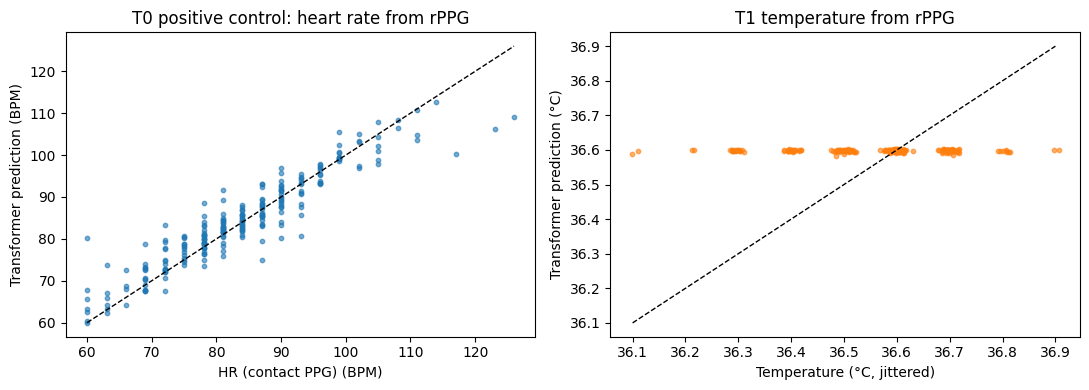

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
te = sess[TE].set_index("sid")
p0 = TR_PRED["T0"]; y0 = te.loc[p0.index, "hr_target"]
ax[0].scatter(y0, p0, s=10, alpha=.6); l = [y0.min(), y0.max()]; ax[0].plot(l, l, "k--", lw=1)
ax[0].set(xlabel=f"{HR_TARGET_NAME} (BPM)", ylabel="Transformer prediction (BPM)",
          title="T0 positive control: heart rate from rPPG")
p1 = TR_PRED["T1"]; y1 = te.loc[p1.index, "temperature"]
ax[1].scatter(y1 + np.random.default_rng(0).normal(0, .01, len(y1)), p1, s=10, alpha=.6, color="tab:orange")
l = [y1.min(), y1.max()]; ax[1].plot(l, l, "k--", lw=1)
ax[1].set(xlabel="Temperature (°C, jittered)", ylabel="Transformer prediction (°C)",
          title="T1 temperature from rPPG")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "w5_fig1_transformer_controls.png"), dpi=130); plt.show()

## Phase 5: Literature comparison
Published temperature results on MCD-rPPG, next to ours. Every MCD number should be read against the constant (~0.093–0.094 °C), because the label barely varies. Rows with `source = this work` are filled from this run.

In [16]:
res = pd.DataFrame(RESULTS)
def best_row(q):
    r = res.query(q, engine="python")
    return r.loc[r["MAE"].idxmin()] if len(r) else None

lit = [
    dict(source="Egorov et al. 2025 (MCD-rPPG paper, arXiv 2508.17924)", input="RGB video", model="1-D FPN (+PhysFormer/RhythmFormer for HR only)",
         temp_MAE=np.nan, constant=np.nan, note="temperature not reported; biomarker table has no temperature row"),
    dict(source="MCD-rPPG-baselines README (frame models)", input="RGB frames", model="CNN frame models",
         temp_MAE="0.094–0.614", constant="≈0.094", note="best ≈ constant"),
    dict(source="MCD-rPPG-baselines README (video model)", input="RGB video", model="R(2+1)D",
         temp_MAE="0.190–0.258", constant="≈0.094", note="worse than constant"),
    dict(source="This work, week 2", input="rPPG / contact-PPG features", model="Ridge/RF/HGB",
         temp_MAE="> 0.093", constant=0.093, note="all methods worse than constant"),
    dict(source="This work, week 4", input="demographics + oracle HR; PhysioNet pooled", model="Ridge/HGB/RF",
         temp_MAE=0.0938, constant=0.0929, note="best pooled prior −0.9 % [−3.2, 0.0]"),
    dict(source="This work, week 4 (PhysioNet, infrared)", input="26 facial IR temperatures", model="RF",
         temp_MAE=0.184, constant=0.307, note="+40 % skill, fever AUC 0.986 (thermal camera, not rPPG)"),
]
for tag, q in [("tabular rPPG + audio", "phase=='P3' and target=='temperature' and ref=='constant' and features.str.contains('audio')"),
               ("tabular rPPG", "phase=='P3' and target=='temperature' and ref=='constant' and features.str.contains('rPPG') and not features.str.contains('audio')"),
               ("transformer (best of T1–T3)", "phase=='P4' and target=='temperature' and features.str.match('T[123]')"),
               ("transformer contact PPG (T4)", "phase=='P4' and target=='temperature' and features.str.startswith('T4')")]:
    r = best_row(q)
    if r is not None:
        lit.append(dict(source=f"This work, week 5: {tag}", input=r.features, model=r.model, temp_MAE=r.MAE,
                        constant=r.ref_MAE, note=f"skill {r.skill_pct:+.1f}% [{r.skill_lo:+.1f}, {r.skill_hi:+.1f}]"))
lit = pd.DataFrame(lit)
lit.to_csv(os.path.join(OUT_DIR, "w5_literature_comparison.csv"), index=False)
display(lit)

,source,input,model,temp_MAE,constant,note
0,"Egorov et al. 2025 (MCD-rPPG paper, arXiv 2508...",RGB video,1-D FPN (+PhysFormer/RhythmFormer for HR only),NaN,NaN,temperature not reported; biomarker table has ...
1,MCD-rPPG-baselines README (frame models),RGB frames,CNN frame models,0.094–0.614,≈0.094,best ≈ constant
2,MCD-rPPG-baselines README (video model),RGB video,R(2+1)D,0.190–0.258,≈0.094,worse than constant
3,"This work, week 2",rPPG / contact-PPG features,Ridge/RF/HGB,> 0.093,0.093,all methods worse than constant
4,"This work, week 4",demographics + oracle HR; PhysioNet pooled,Ridge/HGB/RF,0.0938,0.0929,"best pooled prior −0.9 % [−3.2, 0.0]"
5,"This work, week 4 (PhysioNet, infrared)",26 facial IR temperatures,RF,0.184,0.307,"+40 % skill, fever AUC 0.986 (thermal camera, ..."
6,"This work, week 5: tabular rPPG",demo + rPPG,HGB,0.1027,0.0929,"skill -10.6% [-22.8, -1.3]"
7,"This work, week 5: transformer (best of T1–T3)",T1 rPPG,Transformer,0.0936,0.0929,"skill -0.8% [-1.5, -0.1]"
8,"This work, week 5: transformer contact PPG (T4)",T4 contact PPG (ceiling),Transformer,0.0948,0.0929,"skill -2.0% [-5.1, +0.9]"


## Phase 6: Results and decision gate

In [17]:
res = pd.DataFrame(RESULTS)
res.to_csv(os.path.join(OUT_DIR, "w5_results.csv"), index=False)
cols = ["phase", "target", "model", "features", "n", "MAE", "ref", "ref_MAE", "skill_pct", "skill_lo", "skill_hi",
        "spearman", "pred_sd", "label_sd"]
display(res[cols])

lines = [f"Audio usable on MCD: {AUDIO_USABLE}" + (f" (camera {AUDIO_CAMERA})" if AUDIO_CAMERA else "")]
if AUDIO_CONTROL:
    lines.append(f"Audio positive controls: breathing-rate vs respiratory rho {AUDIO_CONTROL['breath_rho']:+.3f}; "
                 f"before/after AUC {AUDIO_CONTROL['exercise_auc']:.3f}")
for q, tag in [("phase=='P4' and target=='hr_target'", "Transformer positive control (HR)"),
               ("phase=='P4' and target=='temperature'", "Transformer temperature (best)"),
               ("phase=='P4' and target=='shuffled temperature'", "Transformer negative control"),
               ("phase=='P3' and ref=='constant'", "Best tabular temperature")]:
    r = best_row(q)
    if r is not None:
        lines.append(f"{tag}: {r.features} {r.model} MAE {r.MAE} vs {r.ref} {r.ref_MAE} -> skill {r.skill_pct:+.1f}% "
                     f"[{r.skill_lo:+.1f}, {r.skill_hi:+.1f}], rho {r.spearman}, pred sd {r.pred_sd} (label sd {r.label_sd})")
print("\n".join("• " + l for l in lines))
open(os.path.join(OUT_DIR, "w5_summary.txt"), "w").write("\n".join(lines))

,phase,target,model,features,n,MAE,ref,ref_MAE,skill_pct,skill_lo,skill_hi,spearman,pred_sd,label_sd
0,P3,temperature,Ridge,demographics,240,0.1048,constant,0.0929,-12.82,-22.65,-5.36,0.089,0.0050,0.1338
1,P3,temperature,HGB,demographics,240,0.1000,constant,0.0929,-7.62,-18.46,0.87,0.094,0.0457,0.1338
2,P3,temperature,Ridge,rPPG,240,0.1103,constant,0.0929,-18.71,-37.11,-7.05,-0.011,0.0579,0.1338
3,P3,temperature,HGB,rPPG,240,0.1070,constant,0.0929,-15.12,-26.88,-6.19,0.006,0.0350,0.1338
4,P3,temperature,Ridge,demo + rPPG,240,0.1104,constant,0.0929,-18.79,-37.44,-7.05,0.007,0.0599,0.1338
5,P3,temperature,HGB,demo + rPPG,240,0.1027,constant,0.0929,-10.58,-22.77,-1.26,0.120,0.0380,0.1338
6,P4,hr_target,Transformer,T0 rPPG (positive control),240,2.9810,constant,9.3750,68.20,62.77,72.90,0.934,10.5396,12.0327
7,P4,temperature,Transformer,T1 rPPG,240,0.0936,constant,0.0929,-0.76,-1.51,-0.11,0.023,0.0028,0.1338
8,P4,temperature,Transformer,T2 rPPG + demo token,240,0.0957,constant,0.0929,-3.02,-5.52,-1.13,0.043,0.0061,0.1338
9,P4,temperature,Transformer,T4 contact PPG (ceiling),240,0.0948,constant,0.0929,-2.01,-5.10,0.89,-0.034,0.0149,0.1338


NameError: name 'AUDIO_USABLE' is not defined

### How to read this
- **Audio audit:** if `AUDIO_USABLE` is False, the MCD videos have no usable sound, so rPPG + audio cannot be tested on MCD. That is a dataset fact to report, not a failed experiment.
- **Positive control (T0):** the transformer should predict heart rate with large positive skill. If it does, the pipeline and the model work.
- **Temperature (T1–T4):**
  - Skill intervals that include 0, or are negative, mean the transformer finds nothing beyond the constant. The same holds for contact PPG (T4).
  - Check `pred_sd`: values far below `label_sd` mean the model collapsed to near-constant predictions, as the week-4 stress CNN did.
- **Negative control (T5)** must sit at ≈ 0 skill. If T1 ≈ T5, temperature behaves like a shuffled label.
- **Literature:** no published model beats the MCD constant for temperature either, so our result agrees with the dataset authors' own baselines.

### Decision gate
1. **Positive control succeeds, temperature fails (expected).** The limitation is MCD's labels (std 0.13 °C, no fevers), not the model class. Close MCD temperature (rPPG, audio, transformer) and move to data with febrile cases:
   - **LVT** (EURECOM): RGB + thermal video, infrared-thermometer labels. Check its temperature range first; it has no audio.
   - **Own recording** with face video + microphone + reference thermometer, including febrile patients. This is the only way to test rPPG + audio properly.
2. **Positive control fails.** Fix the pipeline (signal cache, windowing, training) before drawing conclusions.
3. **Temperature skill > 0 with an interval above 0** (unexpected). Repeat with repeated grouped CV before believing it. Check that T5 stays at 0 and that no label column leaked into the features.